In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Locate the project root from this notebook
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"

print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATA_DIR)
print("Files found:", [p.name for p in DATA_DIR.iterdir()])


Project root: D:\project\Customer-Churn-Prediction
Dataset directory: D:\project\Customer-Churn-Prediction\data\raw
Files found: ['Telco-Customer-Churn.csv']


In [4]:
df = pd.read_csv("D:\\project\\Customer-Churn-Prediction\\data\\raw\\Telco-Customer-Churn.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:

print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values per column:")
display(df.isna().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
display(df["Churn"].value_counts(dropna=False))

print("\nTarget distribution (%):")
display(
    (df["Churn"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)


Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecur

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


Duplicate rows: 0

Target distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Target distribution (%):


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

In [6]:

# Check blank or whitespace-only values
blank_total_charges = (
    df["TotalCharges"].str.strip().eq("").sum()
)

print("Blank TotalCharges values:", blank_total_charges)

# Convert to numeric for analysis, without modifying the original column yet
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

print("Values that failed numeric conversion:", total_charges_numeric.isna().sum())

display(
    df.loc[total_charges_numeric.isna(), [
        "customerID", "tenure", "TotalCharges", "Churn"
    ]].head(10)
)


Blank TotalCharges values: 11
Values that failed numeric conversion: 11


,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,,No
753,3115-CZMZD,0,,No
936,5709-LVOEQ,0,,No
1082,4367-NUYAO,0,,No
1340,1371-DWPAZ,0,,No
3331,7644-OMVMY,0,,No
3826,3213-VVOLG,0,,No
4380,2520-SGTTA,0,,No
5218,2923-ARZLG,0,,No
6670,4075-WKNIU,0,,No


In [7]:

numerical_data = pd.DataFrame({
    "tenure": df["tenure"],
    "MonthlyCharges": df["MonthlyCharges"],
    "TotalCharges": total_charges_numeric
})

display(numerical_data.describe().round(2))


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
std,24.56,30.09,2266.77
min,0.00,18.25,18.80
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.80


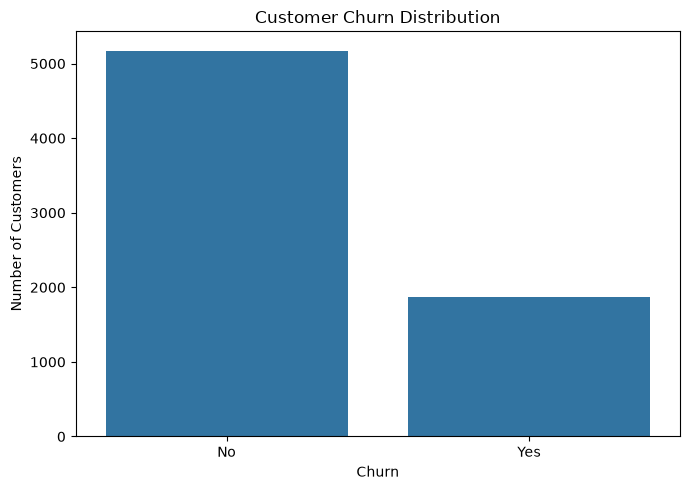

In [8]:

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn",
    order=["No", "Yes"]
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


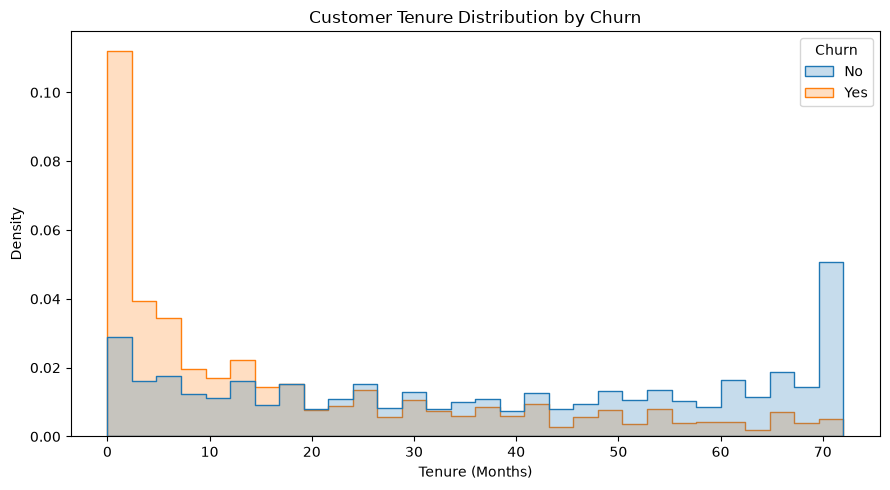

In [9]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


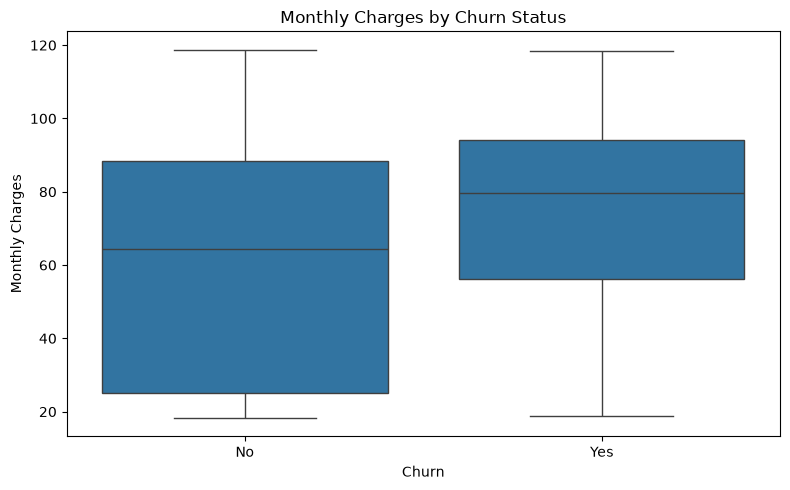

In [10]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    order=["No", "Yes"]
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()


In [11]:

# Categorical features to investigate
categorical_features = [
    "Contract",
    "PaymentMethod",
    "TechSupport",
    "InternetService",
    "OnlineSecurity"
]

# Convert churn labels into a numerical indicator for analysis
churn_numeric = df["Churn"].map({"No": 0, "Yes": 1})

for col in categorical_features:
    summary = (
        df.assign(ChurnNumeric=churn_numeric)
        .groupby(col, dropna=False)
        .agg(
            Customers=("ChurnNumeric", "size"),
            Churn_Rate=("ChurnNumeric", "mean")
        )
        .sort_values("Churn_Rate", ascending=False)
    )

    summary["Churn_Rate"] = (summary["Churn_Rate"] * 100).round(2)

    print(f"\n{'=' * 45}")
    print(f"Churn analysis: {col}")
    display(summary)



Churn analysis: Contract


,Customers,Churn_Rate
Contract,,
Month-to-month,3875,42.71
One year,1473,11.27
Two year,1695,2.83



Churn analysis: PaymentMethod


,Customers,Churn_Rate
PaymentMethod,,
Electronic check,2365,45.29
Mailed check,1612,19.11
Bank transfer (automatic),1544,16.71
Credit card (automatic),1522,15.24



Churn analysis: TechSupport


,Customers,Churn_Rate
TechSupport,,
No,3473,41.64
Yes,2044,15.17
No internet service,1526,7.40



Churn analysis: InternetService


,Customers,Churn_Rate
InternetService,,
Fiber optic,3096,41.89
DSL,2421,18.96
No,1526,7.40



Churn analysis: OnlineSecurity


,Customers,Churn_Rate
OnlineSecurity,,
No,3498,41.77
Yes,2019,14.61
No internet service,1526,7.40


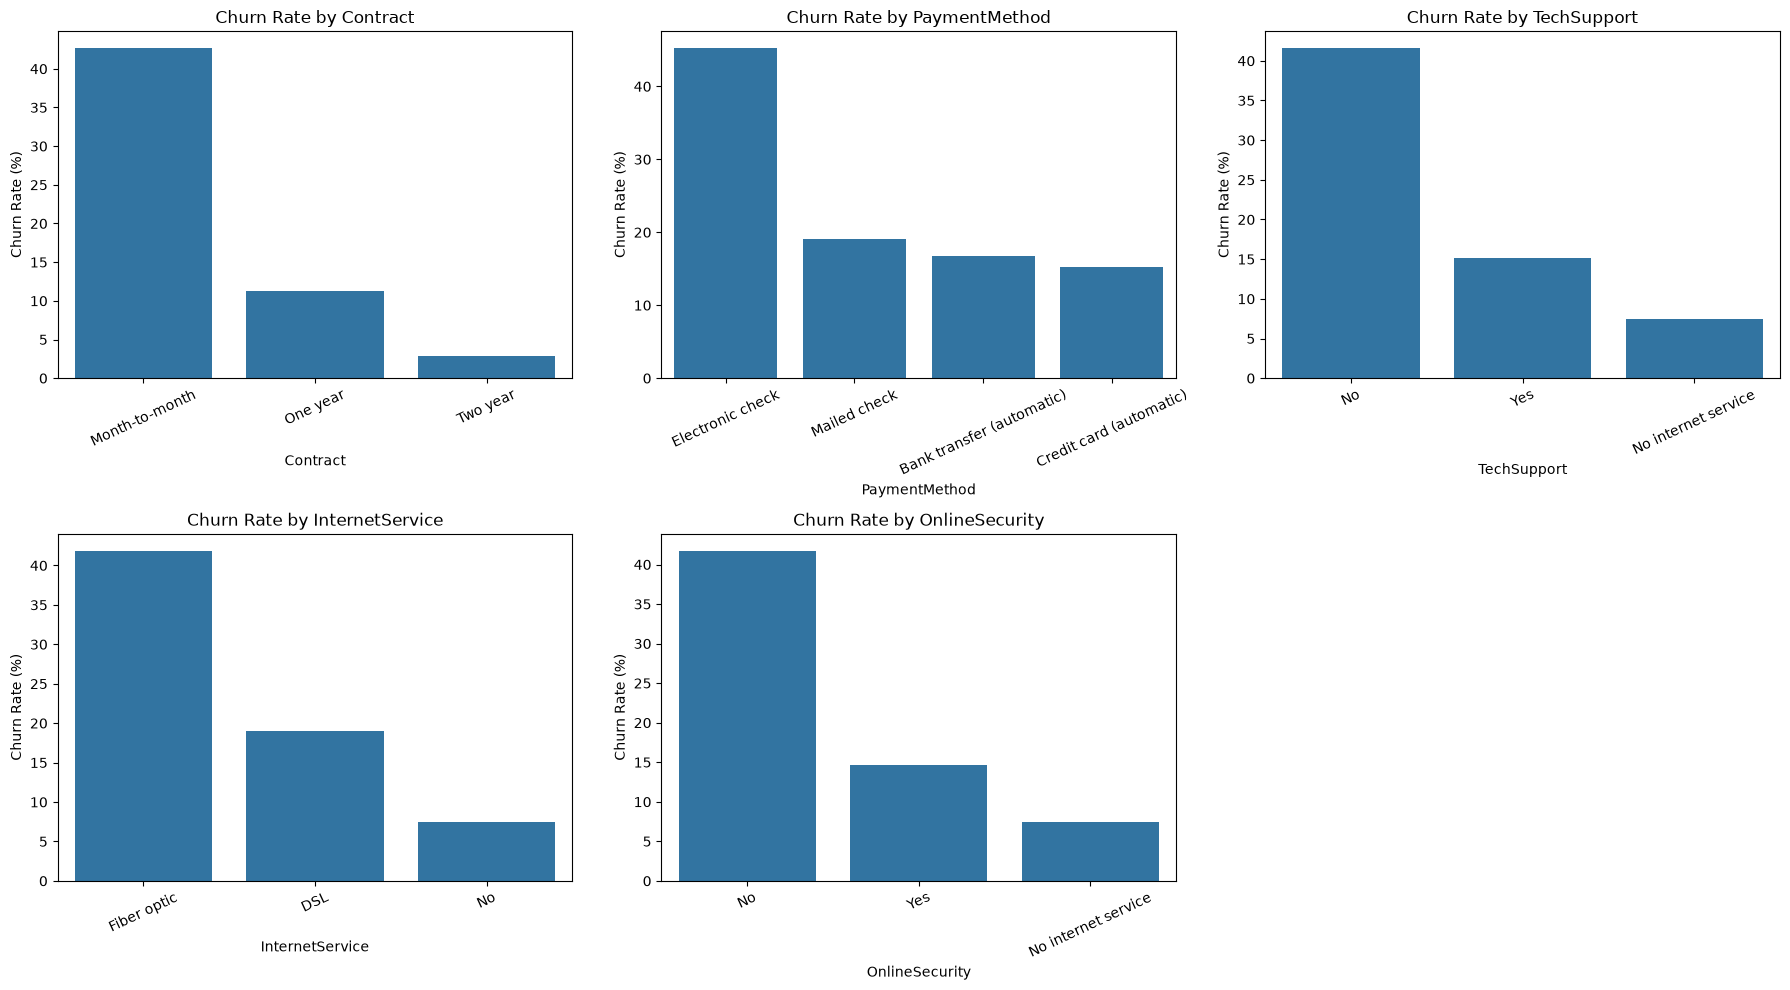

In [12]:

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

plot_data = df.assign(ChurnNumeric=churn_numeric)

for i, col in enumerate(categorical_features):
    rates = (
        plot_data.groupby(col, dropna=False)["ChurnNumeric"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    sns.barplot(
        x=rates.index,
        y=rates.values,
        ax=axes[i]
    )

    axes[i].set_title(f"Churn Rate by {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Churn Rate (%)")
    axes[i].tick_params(axis="x", rotation=25)

# Remove the unused sixth subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()


In [13]:

# Prepare TotalCharges numerically for analysis
eda_df = df.copy()

eda_df["TotalCharges"] = pd.to_numeric(
    eda_df["TotalCharges"].str.strip(),
    errors="coerce"
)

numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

display(
    eda_df.groupby("Churn")[numerical_features]
    .agg(["mean", "median"])
    .round(2)
)


tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2555.34  1683.60
Yes    17.98   10.0          74.44  79.65      1531.80   703.55

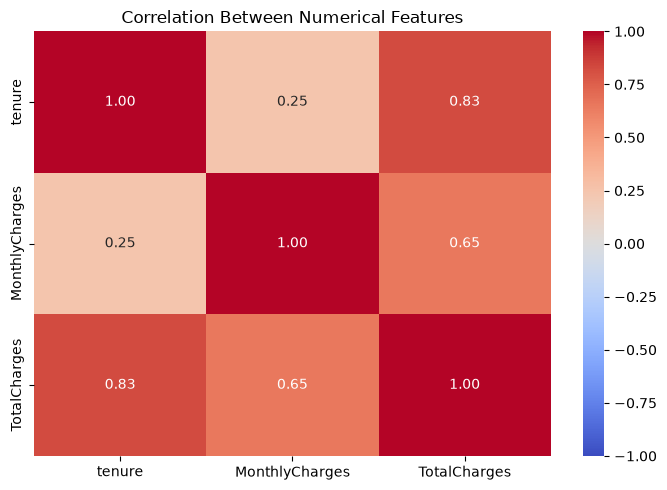

In [15]:

correlation_data = eda_df[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_data,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()


## Exploratory Data Analysis — Initial Findings

- The dataset contains 7,043 customer records and 21 columns.
- The observed churn rate is 26.54%, indicating a moderate class imbalance.
- Eleven blank `TotalCharges` values were identified. All inspected affected customers had zero tenure and a churn label of `No`.
- Month-to-month contracts have a substantially higher churn rate (42.71%) than one-year (11.27%) and two-year contracts (2.83%).
- Electronic-check customers have the highest observed churn rate among payment methods (45.29%).
- Customers without tech support or online security show higher churn rates than customers with these services.
- Fiber-optic customers have a higher observed churn rate (41.89%) than DSL customers (18.96%).
- These patterns are exploratory associations and require evaluation alongside other features in predictive models.